# Lesson 1 — Random variables and characteristic values

Code calibration starts from a *probabilistic model*: every quantity that
enters a design — strengths, model uncertainties, self-weights, climatic
loads — is a random variable with a distribution, a mean and a coefficient
of variation (CoV). The design code, on the other hand, works with a single
*characteristic value* $x_k$ per quantity and partial factors $\gamma$ that
scale it. This lesson shows how the two worlds connect.

What you will see:

1. the three distribution families of the model (normal, lognormal, Gumbel),
2. characteristic values as fractiles,
3. the transformation to standard-normal space that FORM relies on,
4. how a yearly-maximum load becomes a 50-year maximum,
5. the characteristic value of a climatic load by simulation.

Run it cell by cell (Spyder: Ctrl+Enter, VS Code: "Run Cell") or as a script.

In [1]:
import os
import sys

import numpy as np

try:
    import codecal as cc
except ImportError:                     # not installed: run from the lessons/ folder
    sys.path.insert(0, os.path.abspath('..'))
    import codecal as cc
from codecal.plots import Figure

FIG = 'figures'                          # figures are written next to the lesson
os.makedirs(FIG, exist_ok=True)


def save(fig, name):
    """Save a figure next to the lesson and show it (inline in Jupyter/Spyder)."""
    fig.savefig(os.path.join(FIG, name), dpi=150, bbox_inches='tight')
    try:
        from IPython.display import display
        display(fig)
    except ImportError:            # plain python: the PNG in figures/ is the output
        pass

## 1. Three distributions from mean and CoV

All variables of the AHG model are *normalised*: the mean is 1.0. A
distribution is therefore fully described by its family and its CoV.

* **Normal** — self-weights and permanent loads (small scatter, symmetric).
* **Lognormal** — strengths and model uncertainties (positive, skewed; the
  product of lognormal variables is lognormal, which is why FORM likes it).
* **Gumbel** — maxima of time-variant loads over a period (wind, snow, imposed).

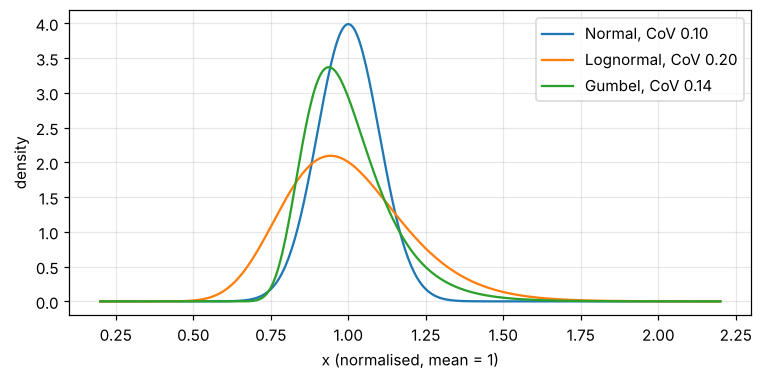

In [2]:
normal = cc.Normal.from_moments(1.0, 0.10)
lognormal = cc.Lognormal.from_moments(1.0, 0.20)
gumbel = cc.Gumbel.from_moments(1.0, 0.14)

x = np.linspace(0.2, 2.2, 400)
fig = Figure(figsize=(8, 3.6))
ax = fig.subplots()
for d, label in [(normal, 'Normal, CoV 0.10'), (lognormal, 'Lognormal, CoV 0.20'), (gumbel, 'Gumbel, CoV 0.14')]:
    ax.plot(x, d.pdf(x), label=label)
ax.set_xlabel('x (normalised, mean = 1)')
ax.set_ylabel('density')
ax.legend()
ax.grid(alpha=0.3)
save(fig, 'lesson01_densities.png')

## 2. Characteristic values are fractiles

Eurocode conventions: strengths use the **5 % fractile**, permanent loads
the **mean** (50 %), climatic loads the **98 % fractile of the yearly
maximum**. The ratio $x_k/\mu$ depends only on the CoV:

In [3]:
print("5 % fractile of a lognormal strength, relative to the mean:")
for cov in (0.05, 0.10, 0.15, 0.20):
    d = cc.Lognormal.from_moments(1.0, cov)
    print(f"  CoV = {cov:.2f}:  x_k/μ = {d.ppf(0.05):.3f}")

5 % fractile of a lognormal strength, relative to the mean:
  CoV = 0.05:  x_k/μ = 0.920
  CoV = 0.10:  x_k/μ = 0.844
  CoV = 0.15:  x_k/μ = 0.774
  CoV = 0.20:  x_k/μ = 0.708


A larger CoV pushes the characteristic value further below the mean — and
that is before any partial factor is applied. Timber (CoV 0.20) starts
from 0.72 where steel (CoV 0.05) starts from 0.92.

The AHG input pins steel at **0.83** and aluminium at 0.85 instead of the
computed 0.92 (a legacy of the June-2021 input — the open question is
recorded in `codecal/ahg2021.py`). The `rv()` helper accepts either form:

In [4]:
steel = cc.rv('Steel yield strength', 'lognormal', 1.0, 0.05, char=0.83)
concrete = cc.rv('Concrete strength', 'lognormal', 1.0, 0.10, fractile=0.05)
print(steel)
print(concrete)

Steel yield strength: Lognormal(mean=1, CoV=0.05), x_k=0.83
Concrete strength: Lognormal(mean=1, CoV=0.1), x_k=0.844


## 3. The transformation to standard-normal space

FORM does not work with the physical variables directly. Each variable $X$
is mapped to a standard-normal variable $U$ by matching the distribution
functions,

$$ \Phi(u) = F_X(x) \quad\Longleftrightarrow\quad x = F_X^{-1}(\Phi(u)) . $$

In $u$-space all variables look alike (mean 0, standard deviation 1,
independent), so "distance from the origin" means "how improbable". The
curves below show how far from linear the mapping is: for the normal it is
a straight line, for the lognormal and the Gumbel the upper tail bends
upwards — a large $u$ corresponds to a very large load.

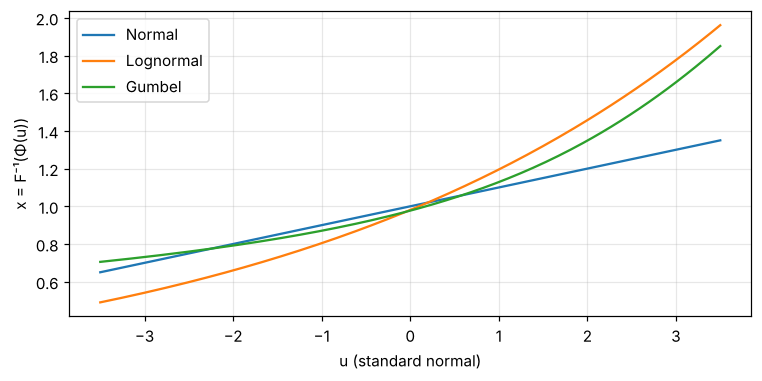

In [5]:
u = np.linspace(-3.5, 3.5, 200)
fig = Figure(figsize=(8, 3.6))
ax = fig.subplots()
for d, label in [(normal, 'Normal'), (lognormal, 'Lognormal'), (gumbel, 'Gumbel')]:
    ax.plot(u, d.x_of_u(u), label=label)
ax.set_xlabel('u (standard normal)')
ax.set_ylabel('x = F⁻¹(Φ(u))')
ax.grid(alpha=0.3)
ax.legend()
save(fig, 'lesson01_transform.png')

## 4. From yearly maximum to 50-year maximum

A Gumbel variable describing the yearly maximum $Q_1$ has distribution
function $F_1$. The maximum over 50 independent years has $F_{50} = F_1^{50}$,
which is again Gumbel with the **same scatter** $\sigma$ and a mean shifted by

$$ \mu_{50} = \mu_1 + \frac{\sqrt 6}{\pi}\,\sigma \ln 50 . $$

The AHG model gives the 50-year maximum with mean 1 and CoV 0.14 for wind.
Going back to the yearly maximum:

50-year maximum: mean 1.000, std 0.140
yearly  maximum: mean 0.573, std 0.140  (CoV 0.244)
check F_50(1.2) = 0.9141 = F_1(1.2)^50 = 0.9141


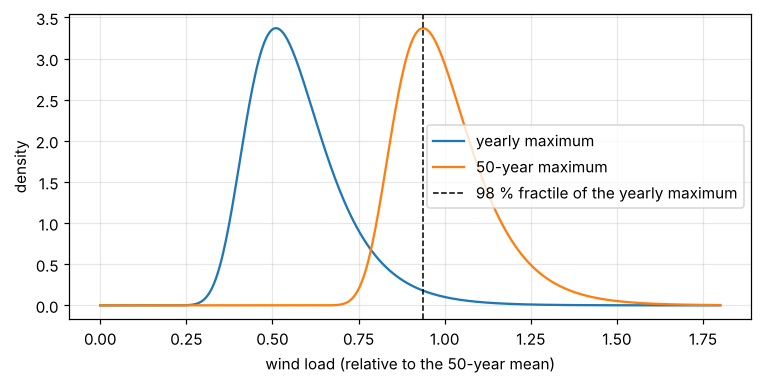

In [6]:
wind_50 = cc.Gumbel.from_moments(1.0, 0.14)
wind_1 = wind_50.over_period(1 / 50)
print(f"50-year maximum: mean {wind_50.mean:.3f}, std {wind_50.std:.3f}")
print(f"yearly  maximum: mean {wind_1.mean:.3f}, std {wind_1.std:.3f}  (CoV {wind_1.cov:.3f})")
print(f"check F_50(1.2) = {wind_50.cdf(1.2):.4f} = F_1(1.2)^50 = {wind_1.cdf(1.2)**50:.4f}")

x = np.linspace(0.0, 1.8, 400)
fig = Figure(figsize=(8, 3.6))
ax = fig.subplots()
ax.plot(x, wind_1.pdf(x), label='yearly maximum')
ax.plot(x, wind_50.pdf(x), label='50-year maximum')
ax.axvline(wind_1.ppf(0.98), color='k', ls='--', lw=1, label='98 % fractile of the yearly maximum')
ax.set_xlabel('wind load (relative to the 50-year mean)')
ax.set_ylabel('density')
ax.legend()
ax.grid(alpha=0.3)
save(fig, 'lesson01_gumbel_periods.png')

## 5. The characteristic value of a climatic load, with model uncertainty

The characteristic wind load is the 98 % fractile of the yearly maximum —
of the load *effect*, which carries a model uncertainty $\Theta_Q$
(lognormal, mean 0.97, CoV 0.26 for wind). The AHG defines $q_k$ on the
product $\Theta_Q \cdot Q_1$. There is no closed form for the fractile of a
lognormal × Gumbel product, so it is simulated. With the seed used
throughout, this reproduces the number of the AHG study, $q_k = 1.083$:

In [7]:
theta_wind = cc.rv('Wind model uncertainty', 'lognormal', 0.97, 0.26, char=1.0)
rng = np.random.RandomState(12345)
Q_wind, Q_wind_yearly = cc.time_variant_load(
    'Wind, 50-year maximum', mean=1.0, cov=0.14, T_input=50, T_basic=1, T_ref=50,
    theta_Q=theta_wind, fractile=0.98, n_mcs=2_000_000, rng=rng)
print(Q_wind)
print(f"without model uncertainty the 98 % fractile would be {Q_wind_yearly.ppf(0.98):.3f}")

Wind, 50-year maximum: Gumbel(mean=1, CoV=0.14), x_k=1.08
without model uncertainty the 98 % fractile would be 0.936


So the characteristic value is about 8 % *above* the mean of the 50-year
maximum. The partial factor $\gamma_Q = 1.5$ is applied on top of that:
the design value of the wind load is $1.5 \times 1.083 = 1.62$ times the
mean 50-year maximum. Whether that is "enough" is exactly what the
reliability analysis of the next lessons decides.

## 6. The whole model at a glance

In [8]:
model = cc.ahg_model(n_mcs=1_000_000)     # 1 M draws for the characteristic values: fast
print(model.summary())

AHG "Reliability Background of the Eurocodes", input of November 2021

reference period 50 a, target β 3.8
9 failure modes × 3 loads × 3 a_G × 10 a_Q = 810 design situations

Failure modes:
  Steel bending: Θ_R mean 1.15 CoV 0.05, R CoV 0.050 (x_k 0.830), γ_M 1.0, a_Q (0.3, 0.8), a_G (0.6, 1.0), w 0.17
  Concrete compression: Θ_R mean 0.97 CoV 0.14, R CoV 0.100 (x_k 0.844), γ_M 1.5, a_Q (0.1, 0.7), a_G (0.6, 1.0), w 0.12
  Concrete bending: Θ_R mean 1.03 CoV 0.07, R CoV 0.045 (x_k 0.928), γ_M 1.15, a_Q (0.1, 0.7), a_G (0.6, 1.0), w 0.4
  Glulam bending: Θ_R mean 1.00 CoV 0.10, R CoV 0.150 (x_k 0.774), γ_M 1.25, a_Q (0.2, 0.8), a_G (0.6, 1.0), w 0.035
  Timber bending: Θ_R mean 1.00 CoV 0.10, R CoV 0.200 (x_k 0.708), γ_M 1.3, a_Q (0.2, 0.8), a_G (0.6, 1.0), w 0.017
  Masonry: Θ_R mean 1.16 CoV 0.18, R CoV 0.160 (x_k 0.760), γ_M 1.5, a_Q (0.1, 0.7), a_G (0.6, 1.0), w 0.12
  Aluminium bending: Θ_R mean 1.27 CoV 0.15, R CoV 0.050 (x_k 0.850), γ_M 1.1, a_Q (0.3, 0.8), a_G (0.6, 1.0), w 0.01

## Exercises

1. What is the 5 % fractile of a *normal* strength with CoV 0.20? Compare
   with the lognormal — which one is more conservative, and why?
2. Compute the characteristic snow load $q_k$ (CoV 0.20 for the 50-year
   maximum, model uncertainty mean 0.81, CoV 0.26). Why is it *below* 1?
3. The imposed load has a basic period of 5 years and a 99 % fractile. Build
   it with `time_variant_load` and compare the simulated $q_k$ with the
   value 1.35 pinned in the AHG input.